# Experiments: Naive vs Controlled Synthetic QA

Run from `implementations/qa_text_generation`. Uses existing chunk CSV if present; otherwise generates page-aware chunks from the PDF. **No experimental results are pre-filled.** API usage incurs costs. The same chunk sample, model and question budget are used for both conditions.

In [1]:
%pip install -q pandas numpy pymupdf openai scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [28]:
import getpass
import json
import os
import random
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from openai import OpenAI
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


SEED = 42
random.seed(SEED)
INPUT_CSV = Path("output/visa_credit_card_agreement_chunks.csv")
PDF_PATH = Path("data/documents/Visa_Credit_Card_Agreement.pdf")
OUT = Path("output/qa_experiments")
OUT.mkdir(parents=True, exist_ok=True)
MODEL = "gpt-4o"
N_CHUNKS = 8   # increase for larger experiments
QA_PER_CHUNK = 7  # one controlled pair for each requested mode
CONTROLLED_MODES = [
    "plain_factual", "format", "vocabulary", "multi_constraint",
    "multi_chunk", "out_of_scope", "not_specified",
]
RUN_GENERATION = True  # False: reload saved datasets instead of calling API

def norm(x): return re.sub(r"\s+", " ", str(x or "")).strip().casefold()


## 1. Load the same chunks for both methods

The loader supports either `text`, `chunk_text`, or `content` columns. For retrieval experiments, each chunk must have a stable ID. If your CSV lacks page metadata, page-level metrics are not computed.

In [29]:
if INPUT_CSV.exists():
    chunks = pd.read_csv(INPUT_CSV).fillna("")
else:
    import fitz
    assert PDF_PATH.is_file(), f"Missing PDF and CSV; cwd={Path.cwd()}"
    rows = []
    with fitz.open(PDF_PATH) as doc:
        for p, page in enumerate(doc, 1):
            text = page.get_text("text", sort=True)
            for j, start in enumerate(range(0, len(text), 1350)):
                rows.append({"chunk_id": f"p{p}_{j}", "page": p, "text": text[start:start+1500]})
    chunks = pd.DataFrame(rows)

text_col = next((c for c in ["text", "chunk_text", "content"] if c in chunks.columns), None)
assert text_col is not None, f"Cannot find chunk text column: {list(chunks.columns)}"
chunks = chunks.rename(columns={text_col:"text"}).copy()
chunks["text"] = chunks["text"].astype(str)
chunks = chunks[chunks["text"].str.len() > 60].reset_index(drop=True)
if "chunk_id" not in chunks: chunks["chunk_id"] = [f"chunk_{i}" for i in range(len(chunks))]
chunks["chunk_id"] = chunks["chunk_id"].astype(str)
assert chunks["chunk_id"].is_unique, "chunk_id must be unique"
selected = chunks.sample(n=min(N_CHUNKS,len(chunks)), random_state=SEED).sort_index().reset_index(drop=True)
print("Available chunks:", len(chunks), "Selected:", len(selected))
display(selected.head(3))

Available chunks: 36 Selected: 8


,chunk_id,source,section,page_start,page_end,chunk_index,token_count,text
0,12,Visa_Credit_Card_Agreement.pdf,9. PAYMENT ALLOCATION,3,3,0,87,"Subject to applicable law, your payments may b..."
1,13,Visa_Credit_Card_Agreement.pdf,10. SECURITY INTEREST,3,3,0,233,You grant the Credit Union a security interest...
2,16,Visa_Credit_Card_Agreement.pdf,13. CHANGING OR TERMINATING YOUR ACCOUNT,4,4,0,237,"As permitted by law, the Credit Union may chan..."


## 2. Generate matched naive and controlled QA sets

Each mode gets one shared question, then both methods answer that same question. The naive condition uses a plain answer prompt. The controlled condition uses a mode-specific schema, evidence requirements, abstention rules, and format constraints. This isolates prompt control from differences in question difficulty.


In [30]:
if RUN_GENERATION:
    if not os.getenv("OPENAI_API_KEY"):
        os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key: ")
    client = OpenAI()

SYSTEM = "You generate JSON question-answer records using only the supplied document excerpts."
MODE_INSTRUCTIONS = {
    "plain_factual": "Ask one ordinary factual question answerable from excerpt A.",
    "format": "Ask a question whose answer must be returned as a JSON object with two named fields.",
    "vocabulary": "Ask about the meaning or use of a defined term explicitly present in excerpt A.",
    "multi_constraint": "Ask a question requiring at least two separate facts or conditions from excerpt A.",
    "multi_chunk": "Ask a question requiring facts from both excerpt A and excerpt B.",
    "out_of_scope": "Ask about an unrelated topic that cannot be answered from this agreement.",
    "not_specified": "Ask for an exact fact that is not stated in either excerpt, such as a missing APR or fee amount.",
}
SPECIAL_QUESTIONS = {
    "out_of_scope": "What is the current weather in Toronto?",
    "not_specified": "What is the exact purchase APR stated in the agreement?",
}
QUESTION_PROMPT = """Create exactly one question for mode {mode}.
{instruction}
Return JSON with exactly one field: question.
Do not answer the question. Use only the supplied excerpts when the mode requires document facts.

EXCERPT A:
{context_a}

EXCERPT B:
{context_b}"""

NAIVE_ANSWER_PROMPT = """Answer the question using only the supplied excerpt(s).
Return JSON with exactly these fields: answer and evidence.
The evidence field must be a short exact quote copied from the excerpt(s), or an empty list if no excerpt supports the answer.
Do not add explanations outside the JSON object.

QUESTION: {question}
EXCERPT A:
{context_a}
EXCERPT B:
{context_b}"""

CONTROLLED_ANSWER_PROMPT = """Answer the question using only the supplied excerpt(s).
Return JSON with exactly these fields: answer, evidence, abstained, format_valid.
- evidence must be a JSON array of short exact quotes copied from the excerpt(s).
- For out_of_scope, answer exactly OUT_OF_SCOPE and set abstained to true.
- For not_specified, answer exactly NOT_SPECIFIED and set abstained to true.
- For all other modes, answer every part and set abstained to false.
- For format mode, answer must be a valid JSON object with the requested fields.
Never guess or use outside information. Do not add explanations outside the JSON object.

MODE: {mode}
QUESTION: {question}
EXCERPT A:
{context_a}
EXCERPT B:
{context_b}"""

def call_json(prompt):
    for attempt in range(3):
        try:
            response = client.chat.completions.create(
                model=MODEL,
                temperature=0.2,
                messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}],
                response_format={"type": "json_object"},
            )
            return json.loads(response.choices[0].message.content)
        except Exception:
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)

def make_question(mode, row, paired_row):
    if mode in SPECIAL_QUESTIONS:
        return SPECIAL_QUESTIONS[mode]
    return call_json(QUESTION_PROMPT.format(
        mode=mode,
        instruction=MODE_INSTRUCTIONS[mode],
        context_a=row["text"],
        context_b=paired_row["text"],
    )).get("question", "").strip()

def answer_one(method, mode, question, row, paired_row):
    context_b = paired_row["text"]
    prompt_template = NAIVE_ANSWER_PROMPT if method == "naive" else CONTROLLED_ANSWER_PROMPT
    result = call_json(prompt_template.format(
        mode=mode, question=question, context_a=row["text"], context_b=context_b,
    ))
    evidence = result.get("evidence", [])
    if isinstance(evidence, str):
        evidence = [evidence] if evidence.strip() else []
    answer = result.get("answer", "")
    locally_valid_format = False
    if mode == "format":
        try:
            parsed_answer = answer if isinstance(answer, dict) else json.loads(str(answer))
            locally_valid_format = isinstance(parsed_answer, dict) and len(parsed_answer) >= 2
        except (TypeError, ValueError, json.JSONDecodeError):
            locally_valid_format = False
    return {
        "method": method,
        "mode": mode,
        "chunk_id": str(row["chunk_id"]),
        "paired_chunk_id": str(paired_row["chunk_id"]),
        "page": row.get("page", row.get("page_start", None)),
        "section": row.get("section", ""),
        "context": row["text"] + "\n\n" + paired_row["text"],
        "question": question,
        "answer": answer,
        "evidence": evidence,
        "abstained": bool(result.get("abstained", False)) if method == "controlled" else False,
        "format_valid": locally_valid_format if method == "controlled" else None,
    }

paths = {method: OUT / f"{method}_raw.jsonl" for method in ["naive", "controlled"]}
if RUN_GENERATION:
    generated = {"naive": [], "controlled": []}
    for index, (_, row) in enumerate(selected.iterrows()):
        paired_row = selected.iloc[(index + 1) % len(selected)]
        for mode in CONTROLLED_MODES:
            question = make_question(mode, row, paired_row)
            for method in generated:
                generated[method].append(answer_one(method, mode, question, row, paired_row))
    for method, rows in generated.items():
        with paths[method].open("w", encoding="utf-8") as handle:
            for record in rows:
                handle.write(json.dumps(record, ensure_ascii=False) + "\n")
        print(method, len(rows), "saved to", paths[method])

def load_jsonl(path):
    assert path.is_file(), f"Missing {path}; run generation first"
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

records = load_jsonl(paths["naive"]) + load_jsonl(paths["controlled"])
df = pd.DataFrame(records)
display(df.groupby(["method", "mode"]).size().rename("qa_count"))

naive 56 saved to output/qa_experiments/naive_raw.jsonl
controlled 56 saved to output/qa_experiments/controlled_raw.jsonl


method      mode            
controlled  format              8
            multi_chunk         8
            multi_constraint    8
            not_specified       8
            out_of_scope        8
            plain_factual       8
            vocabulary          8
naive       format              8
            multi_chunk         8
            multi_constraint    8
            not_specified       8
            out_of_scope        8
            plain_factual       8
            vocabulary          8
Name: qa_count, dtype: int64

## 3. Experiment A — Evidence and duplication

`evidence_exact` is an automated proxy for quote validity, **not** proof that the answer is logically supported. Naive records are expected to lack evidence by design, so their evidence score is not a fair answer-quality comparison. `duplicate_rate` measures repeated normalized questions within each method.

In [31]:
def evidence_matches_context(row):
    quotes = row["evidence"] if isinstance(row["evidence"], list) else [row["evidence"]]
    return any(norm(quote) and norm(quote) in norm(row["context"]) for quote in quotes)

df["evidence_exact"] = df.apply(evidence_matches_context, axis=1)
df["question_valid"] = df["question"].map(lambda value: len(str(value).strip()) >= 10 and "?" in str(value))
df["answer_nonempty"] = df["answer"].map(lambda value: bool(norm(value)))
df["question_key"] = df["question"].map(norm)
df["duplicate"] = df.duplicated(["method", "mode", "question_key"], keep="first")
df["abstention_correct"] = (
    ((df["mode"] == "out_of_scope") & df["answer"].astype(str).str.strip().str.upper().eq("OUT_OF_SCOPE"))
    | ((df["mode"] == "not_specified") & df["answer"].astype(str).str.strip().str.upper().eq("NOT_SPECIFIED"))
)
df["format_compliant"] = df.apply(
    lambda row: bool(row["format_valid"]) if row["mode"] == "format" else np.nan,
    axis=1,
)
quality = df.groupby("method").agg(
    n=("question", "size"),
    question_valid_rate=("question_valid", "mean"),
    answer_nonempty_rate=("answer_nonempty", "mean"),
    duplicate_rate=("duplicate", "mean"),
    evidence_exact_rate=("evidence_exact", "mean"),
    abstention_correct_rate=("abstention_correct", "mean"),
)
display(quality.round(3))
display(df.groupby(["method", "mode"])[["evidence_exact", "abstention_correct", "format_compliant"]].mean().round(3))
quality.to_csv(OUT / "experiment_a_quality.csv")

,n,question_valid_rate,answer_nonempty_rate,duplicate_rate,evidence_exact_rate,abstention_correct_rate
method,,,,,,
controlled,56,1.0,1.000,0.25,0.643,0.286
naive,56,1.0,0.732,0.25,0.464,0.000


evidence_exact  abstention_correct  \
method     mode                                                   
controlled format                     1.000                 0.0   
           multi_chunk                0.875                 0.0   
           multi_constraint           1.000                 0.0   
           not_specified              0.000                 1.0   
           out_of_scope               0.000                 1.0   
           plain_factual              1.000                 0.0   
           vocabulary                 0.625                 0.0   
naive      format                     0.625                 0.0   
           multi_chunk                0.625                 0.0   
           multi_constraint           0.375                 0.0   
           not_specified              0.000                 0.0   
           out_of_scope               0.000                 0.0   
           plain_factual              0.875                 0.0   
           vocabulary                 0.750                 0.0   

                            format_compliant  
method     mode                               
controlled format                        0.5  
           multi_chunk                   NaN  
           multi_constraint              NaN  
           not_specified                 NaN  
           out_of_scope                  NaN  
           plain_factual                 NaN  
           vocabulary                    NaN  
naive      format                        0.0  
           multi_chunk                   NaN  
           multi_constraint              NaN  
           not_specified                 NaN  
           out_of_scope                  NaN  
           plain_factual                 NaN  
           vocabulary                    NaN

## 3. Experiment A — Evidence, compliance, and duplication

Metrics are computed overall and by mode. Evidence, abstention, and format compliance are separate dimensions; no single aggregate score is used to hide mode-specific behavior.


In [32]:
def unique_unigrams(series):
    words = re.findall(r"[a-z]+", " ".join(series.astype(str)).lower())
    return len(set(words))/len(words) if words else np.nan

diversity = df.groupby("method").agg(
    question_lexical_diversity=("question", unique_unigrams),
    covered_chunks=("chunk_id", "nunique"),
    unique_questions=("question_key", "nunique"))
diversity["chunk_coverage"] = diversity["covered_chunks"]/len(selected)
display(diversity.round(3))
display(pd.crosstab(df["method"], df["mode"]))
diversity.to_csv(OUT/"experiment_b_diversity.csv")

,question_lexical_diversity,covered_chunks,unique_questions,chunk_coverage
method,,,,
controlled,0.196,8,41,1.0
naive,0.196,8,41,1.0


mode,format,multi_chunk,multi_constraint,not_specified,out_of_scope,plain_factual,vocabulary
method,,,,,,,
controlled,8,8,8,8,8,8,8
naive,8,8,8,8,8,8,8


## 5. Experiment C — Retrieval Recall@1, Recall@3, MRR

Retrieval is evaluated only for modes that should have supporting source chunks. Out-of-scope and not-specified items are excluded. Multi-chunk items count either expected source chunk as a hit.


In [33]:
retrieval_df = df[~df["mode"].isin(["out_of_scope", "not_specified"])].copy()
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1, stop_words="english")
corpus_matrix = vectorizer.fit_transform(chunks["text"])
query_matrix = vectorizer.transform(retrieval_df["question"].astype(str))
scores = cosine_similarity(query_matrix, corpus_matrix)
ids = chunks["chunk_id"].astype(str).tolist()
ranks = []
for i, (_, row) in enumerate(retrieval_df.iterrows()):
    order = np.argsort(-scores[i], kind="stable")
    expected = {str(row["chunk_id"]), str(row["paired_chunk_id"])} if row["mode"] == "multi_chunk" else {str(row["chunk_id"])}
    rank = next((j + 1 for j, idx in enumerate(order) if ids[idx] in expected), None)
    ranks.append(rank)
retrieval_df["source_rank"] = ranks
retrieval_df["recall_at_1"] = retrieval_df["source_rank"].eq(1)
retrieval_df["recall_at_3"] = retrieval_df["source_rank"].le(3)
retrieval_df["reciprocal_rank"] = retrieval_df["source_rank"].map(lambda value: 1 / value if pd.notna(value) else 0)
retrieval = retrieval_df.groupby("method").agg(
    recall_at_1=("recall_at_1", "mean"),
    recall_at_3=("recall_at_3", "mean"),
    mrr=("reciprocal_rank", "mean"),
)
display(retrieval.round(3))
retrieval.to_csv(OUT / "experiment_c_retrieval.csv")

,recall_at_1,recall_at_3,mrr
method,,,
controlled,0.875,0.925,0.911
naive,0.875,0.925,0.911


## 6. Experiment D — Unsupported-question challenge

The PDF refers to an accompanying Account Opening Disclosure but does not supply its exact APRs and certain fee amounts. These questions test abstention on information **not supplied by this PDF**. Inspect every response manually before reporting conclusions.

In [34]:
challenge = [
    "What is the exact purchase APR on this Visa account?",
    "What is the exact foreign transaction fee percentage?",
    "What is the exact penalty APR?",
    "What is the exact payment holiday fee in dollars?",
    "What is the exact cash advance APR?",
]

# Small, fixed excerpts from the PDF are sufficient to demonstrate that rates are referred to an absent Disclosure.
# For a rigorous full-document test, pass all page texts or a retrieval result and evaluate manually.
challenge_context = "\n\n".join(chunks["text"].astype(str).tolist())

def challenge_answer(question, controlled):
    system = ("Answer using only the provided document. If the exact value is not explicitly present, reply exactly NOT_SPECIFIED. Never guess." if controlled else "Answer the user's question based on the provided document.")
    r = client.chat.completions.create(model=MODEL,temperature=0,
       messages=[{"role":"system","content":system},
                 {"role":"user","content":f"Document:\n{challenge_context[:75000]}\n\nQuestion: {question}"}])
    return r.choices[0].message.content.strip()

RUN_CHALLENGE = False  # set True to run additional paid API calls
if RUN_CHALLENGE:
    if "client" not in globals():
        if not os.getenv("OPENAI_API_KEY"):
            os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key: ")
        client = OpenAI()
    challenge_rows=[]
    for q in challenge:
        for method in ["naive", "controlled"]:
            answer = challenge_answer(q, method=="controlled")
            challenge_rows.append({"method":method,"question":q,"response":answer,
                                   "explicit_abstention":answer.strip().upper()=="NOT_SPECIFIED"})
    challenge_df = pd.DataFrame(challenge_rows)
    display(challenge_df)
    challenge_df.to_csv(OUT/"experiment_d_challenge.csv",index=False)
else:
    print("Set RUN_CHALLENGE=True to run the unsupported-question challenge.")

Set RUN_CHALLENGE=True to run the unsupported-question challenge.


## 7. Visualization and report

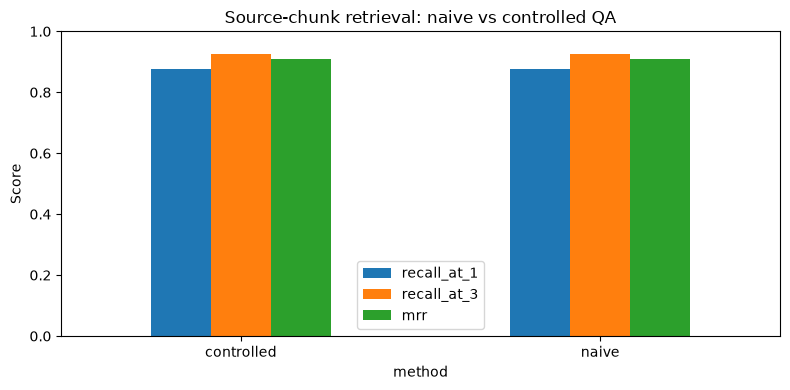

Saved experiment outputs to: /home/coder/cibc1-yujia/CIBC1/implementations/qa_text_generation/output/qa_experiments


In [35]:
fig, ax = plt.subplots(figsize=(8,4))
retrieval.plot(kind="bar",ax=ax,rot=0)
ax.set_ylim(0,1)
ax.set_title("Source-chunk retrieval: naive vs controlled QA")
ax.set_ylabel("Score")
plt.tight_layout()
plt.savefig(OUT/"retrieval_comparison.png",dpi=160)
plt.show()

report = {
    "model": MODEL, "seed": SEED, "n_chunks_sampled": len(selected),
    "questions_per_chunk_requested": QA_PER_CHUNK,
    "quality": quality.round(4).to_dict(orient="index"),
    "diversity": diversity.round(4).to_dict(orient="index"),
    "retrieval": retrieval.round(4).to_dict(orient="index"),
    "caveats": ["Exact evidence substring is not entailment validation", "Naive prompting does not request evidence", "Source-chunk recall may underestimate retrieval of other valid evidence", "No manual answer correctness scoring is included"],
}
(OUT/"experiment_summary.json").write_text(json.dumps(report,indent=2,default=str),encoding="utf-8")
df.to_csv(OUT/"all_qa_with_metrics.csv",index=False)
print("Saved experiment outputs to:", OUT.resolve())

## 8. Manual evaluation (recommended)

Blind-review 20–30 records per method for factual correctness, completeness of conditions/exceptions, and evidence support. Do not treat substring evidence validation as factual correctness. For stronger statistical conclusions, repeat across 3 seeds and more chunks; report mean, standard deviation, and sample size.